# Data Collation
This notebook does not do much. It runs the data_ingestion notebook in a loop over the the bag_file list and saves all the outputs into one pickle.

So the data_ingestion should return a dict with all the dataframes, params, settings, etc. This is easily pickleable.

The data is merged into one DataFrame named like `concrete_slip_data` with columns:

* slip_ratio_FR
* slip_ratio_BR
* slip_ratio_FL
* slip_ratio_BL

* slip_vx_FR
* slip_vx_BR
* slip_vx_FL
* slip_vx_BL

* slip_vy_FR
* slip_vy_BR
* slip_vy_FL
* slip_vy_BL

* current_FR
* current_BR
* current_FL
* current_BL

* torque_FR
* torque_BR
* torque_FL
* torque_BL

* vx_FR
* vx_BR
* vx_FL
* vx_BL




In [23]:
import papermill as pm
from pathlib import Path
import os
from datetime import datetime


In [10]:
# Make three lists of rosbags: Concrete, vinyl, melamine
concrete_rosbags = [
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_30_34_distance_triangle_3.0base_0.001amp_0.3hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_34_09_distance_triangle_3.0base_3.0amp_0.3hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_35_20_distance_triangle_3.0base_3.0amp_0.5hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_38_09_distance_triangle_3.0base_3.0amp_0.8hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_41_22_distance_triangle_3.0base_3.0amp_1.0hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_42_48_distance_triangle_3.0base_3.0amp_1.3hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_44_07_distance_triangle_3.0base_3.0amp_1.5hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_46_40_distance_triangle_3.0base_3.0amp_1.8hz_8.0m_no_shutdown_concrete.bag",
    "2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_53_38_distance_triangle_3.0base_3.0amp_2.0hz_8.0m_no_shutdown_concrete.bag",
]

vinyl_rosbags = [
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__16_58_53_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_01_04_distance_triangle_3.0base_3.0amp_0.3hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_02_23_distance_triangle_3.0base_3.0amp_0.5hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_03_47_distance_triangle_3.0base_3.0amp_0.8hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_05_09_distance_triangle_3.0base_3.0amp_1.0hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_07_05_distance_triangle_3.0base_3.0amp_1.2hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_10_07_distance_triangle_3.0base_3.0amp_1.8hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_11_28_distance_triangle_3.0base_3.0amp_1.5hz_7.0m_no_shutdown_vinyl.bag",
    "2025_6_12_distance_rosbags/2025_6_12_vinyl_bags/2025_6_12__17_12_50_distance_triangle_3.0base_3.0amp_2.0hz_7.0m_no_shutdown_vinyl.bag",
]

melamine_rosbags = [
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_17_01_distance_triangle_3.0base_3.0amp_0.3hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_18_15_distance_triangle_3.0base_3.0amp_0.5hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_19_37_distance_triangle_3.0base_3.0amp_0.8hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_21_05_distance_triangle_3.0base_3.0amp_1.0hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_22_29_distance_triangle_3.0base_3.0amp_1.3hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_23_46_distance_triangle_3.0base_3.0amp_1.5hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_25_23_distance_triangle_3.0base_3.0amp_1.8hz_7.0m_no_shutdown_board.bag",
    "2025_6_12_distance_rosbags/2025_6_12_melamine_bags/2025_6_12__17_26_56_distance_triangle_3.0base_3.0amp_2.0hz_7.0m_no_shutdown_board.bag",
]

robag_dir = "rosbags/"

all_rosbags = {
    "concrete": concrete_rosbags,
    "vinyl": vinyl_rosbags,
    "melamine": melamine_rosbags,
}

In [ ]:
# Now run the data_ingestion notebook in three groups over each rosbag in the
# group. Place the output pickles in an appropriately named dir.


# Func to run our notebook.
def run_data_ingest(
    params,
    nb_path="data_ingestion.ipynb",
    output_path="output_notebooks/preprocess-out.ipynb",
) -> None:
    print(params)
    pm.execute_notebook(
        input_path=nb_path,
        output_path=output_path,
        parameters=params,
        kernel_name="python3",
        progress_bar=True,
        log_output=True,
    )


now = datetime.now().strftime("%Y_%m_%d_%H_%M_%S")


# Create new dir to hold everything
out_dir = Path(f"results/{now}/")
out_dir.mkdir(parents=True, exist_ok=True)

# for surface, rosbags in all_rosbags.keys():
for surface_name, bag_list in all_rosbags.items():
    # Make a dir for each surface type.
    surface_dir = out_dir / Path(f"{surface_name}")
    surface_dir.mkdir(parents=True, exist_ok=True)

    for bagfile in bag_list:
        print(f"Processing {bagfile}")

        just_bag = os.path.basename(bagfile).replace(".bag", "")
        notebook_out = surface_dir / f"data_ingest_{just_bag}.ipynb"
        artifact_dir = surface_dir / f"artifacts_{just_bag}"
        artifact_dir.mkdir(exist_ok=True)

        # just_bag = os.path.basename(bagfile)
        # output_path = f"{surface_dir}/data_ingestion{just_bag}.ipynb"

        params = {
            "bag_path": robag_dir + bagfile,
            "log_level": "INFO",
            "surface_name": surface_name,
            "artifact_dir": str(artifact_dir),
            'owner_dir': str(surface_dir)
        }
        run_data_ingest(
            nb_path="data_ingestion.ipynb",
            output_path=str(notebook_out),
            params=params,
        )

Unable to parse line 78 'artifact_dir.mkdir(parents=True, exist_ok=True)'.
/home/rb/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Processing 2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_30_34_distance_triangle_3.0base_0.001amp_0.3hz_8.0m_no_shutdown_concrete.bag
{'bag_path': 'rosbags/2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_30_34_distance_triangle_3.0base_0.001amp_0.3hz_8.0m_no_shutdown_concrete.bag', 'log_level': 'INFO', 'surface_name': 'concrete', 'artifact_dir': 'results/2025_06_30_00_46_48/concrete/artifacts_2025_6_12__16_30_34_distance_triangle_3.0base_0.001amp_0.3hz_8.0m_no_shutdown_concrete', 'owner_dir': 'results/2025_06_30_00_46_48/concrete'}


Executing:   3%|▎         | 4/127 [00:01<00:41,  2.98cell/s]00:46:49 INFO: Logging is now at INFO level

Executing:   7%|▋         | 9/127 [00:01<00:15,  7.70cell/s]00:46:49 INFO: Opening: bag_path=PosixPath('rosbags/2025_6_12_distance_rosbags/2025_6_12_concrete_bags/2025_6_12__16_30_34_distance_triangle_3.0base_0.001amp_0.3hz_8.0m_no_shutdown_concrete.bag')

00:46:49 INFO: Looking for rosbag in /home/rb/retail-bot/analysis/

00:46:49 INFO: Found bagfile!

Executing:  10%|█         | 13/127 [00:02<00:22,  5.09cell/s]00:46:50 INFO: No messages on topic_name='/parameter_events'

00:46:51 INFO: No messages on topic_name='/vrpn_mocap/melamine_sheet/accel'

00:46:51 INFO: No messages on topic_name='/vrpn_mocap/melamine_sheet/twist'

00:46:51 INFO: No messages on topic_name='/vrpn_mocap/vinyl_sheet/twist'

00:46:51 INFO: No messages on topic_name='/events/write_split'

00:46:51 INFO: No messages on topic_name='/vrpn_mocap/vinyl_sheet/pose'

00:46:51 INFO: No messages on topic_name='/vrpn_moc

KeyboardInterrupt: 

In [24]:
import sys
import os
import pickle
import pandas as pd

# Open all the pickles and plot all the k plots.
print(os.getcwd())
# Open all *.pkl files in this path.
# pickles_path = "results/2025_06_27_22_57_27/melamine_pickles"
# pickles_path = "results/2025_06_29_17_16_40"
pickles_path = 'results/2025_06_29_20_53_41'

# robot & patch parameters
mass = 40.0  # kg
F_N_net = 9.81 * mass  # total normal force (N)
F_N = F_N_net / 4  # per patch
radius = 0.127  # m


# List all .pkl files
pkl_files = [f for f in os.listdir(pickles_path) if f.endswith(".pkl")]
print(pkl_files)

contents = []
for fname in pkl_files:
    fpath = os.path.join(pickles_path, fname)

    with open(fpath, "rb") as f:
        obj = pickle.load(f)
        contents.append(obj)


# Combine Everything
pair_map = {
    "left_front_torque": "fl_vx",
    "right_front_torque": "fr_vx",
    "left_back_torque": "bl_vx",
    "right_back_torque": "br_vx",
}

# Hold all the mu and slip merged in from all the other dataframs.
all_mu = pd.DataFrame()
all_slip = pd.DataFrame()

for each in contents:
    final_df = each["final_df"]
    torq_df = final_df["motor_torques_combined"][pair_map.keys()]

    mu_df = (torq_df / radius) / F_N  # dimensionless μ
    slip_df = final_df["slip_unbiased"]

    if isinstance(slip_df.columns, pd.MultiIndex):
        slip_df = slip_df.droplevel(0, axis=1)
    slip_df = slip_df[list(pair_map.values())]

    all_mu = pd.concat([all_mu, mu_df], axis=0)
    all_slip = pd.concat([all_slip, slip_df], axis=0)

# all_slip["bl_vx"].plot()


/home/rb/retail-bot/analysis
[]


In [25]:
# import numpy as np
# import matplotlib.pyplot as plt

# # robot & patch parameters
# mass = 40.0  # kg
# F_N_net = 9.81 * mass  # total normal force (N)
# F_N = F_N_net / 4  # per patch
# radius = 0.127  # m

# min_s = 1
# max_s = 50

# # ------------------------------------------------------------
# # 0)  define how the torque columns map to the slip columns
# # ------------------------------------------------------------
# pair_map = {  # torque_col       →   slip_col
#     "left_front_torque": "fl_vx",
#     "right_front_torque": "fr_vx",
#     "left_back_torque": "bl_vx",
#     "right_back_torque": "br_vx",
# }

# # ------------------------------------------------------------
# # 1)  build μ  (same units, same index as torque)
# # ------------------------------------------------------------
# # torq_df = final_df["motor_torques_combined"][pair_map.keys()]  # keep only 4 wanted cols
# # mu_df = (torq_df / radius) / F_N  # dimensionless μ

# # ------------------------------------------------------------
# # 2)  slice slip table to the 4 matching cols
# # ------------------------------------------------------------
# # slip_df = final_df["slip_unbiased"]

# mu_df = all_mu
# slip_df = all_slip

# # assert slip_df.index.is_monotonic_increasing


# if isinstance(slip_df.columns, pd.MultiIndex):
#     slip_df = slip_df.droplevel(0, axis=1)
# slip_df = slip_df[list(pair_map.values())]  # ['fl_vx','fr_vx',...]

# # ------------------------------------------------------------
# # 3)  align timestamps, join each wheel’s pair
# # ------------------------------------------------------------
# records = []
# for tq_col, sl_col in pair_map.items():
#     # interpolate torque to slip times so shapes match
#     mu_align = mu_df[tq_col].reindex(slip_df.index).interpolate("index")

#     # collect rows where both are finite
#     pair = pd.DataFrame(
#         {
#             "wheel": sl_col[:-3],  # 'fl','fr','bl','br'
#             "slip_pct": slip_df[sl_col],
#             "mu": mu_align,
#         }
#     ).dropna()

#     records.append(pair)

# paired = pd.concat(records, ignore_index=True)

# # Clip?
# paired = paired[paired["mu"].between(-1.5, 1.5)]


# # Mask out slip values outside range.
# paired = paired[paired["slip_pct"].abs().between(min_s, max_s)]

# paired["slip_frac"] = paired["slip_pct"] / 100.0
# print("sample rows:", len(paired))

# # ------------------------------------------------------------
# # 4)  line fit   μ = k·s + b
# # ------------------------------------------------------------
# k, b = np.polyfit(paired["slip_frac"], paired["mu"], 1)
# # final_vals['f"/{k}_all_slip_slope_min_{min_s}_max{max_s}'] = k
# print(f"k = {k:.3f},  b = {b:.3f}")

# # ------------------------------------------------------------
# # 5)  scatter
# # ------------------------------------------------------------
# plt.figure(figsize=(8, 6))
# plt.scatter(paired["slip_frac"], paired["mu"], s=10, alpha=0.05)
# x = np.linspace(paired["slip_frac"].min(), paired["slip_frac"].max(), 200)
# plt.plot(x, k * x + b, "r-", lw=2, label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.title(
#     f"Slip-Slope, $N=${len(paired)} \n $s \\in [{min_s},{max_s}]\\%$,   $k =${k:.3f}   All Merged Data Vinyl"
# )
# # plt.title(f'Slip-Slope \n $s \\in [{min_s},{max_s}]\\%$,   $k =${k:.3f}    \n{metadata['plot_subtitle']}')
# plt.ylabel(ylabel="μ")
# plt.grid(True)
# plt.tight_layout()
# plt.axis("square")
# # plt.ylim((-.5,.5))
# plt.legend()

# # plt.gcf().savefig(
# #     metadata["artifact_dir"] + f"/{k}_all_slip_slope_min_{min_s}_max{max_s}.png",
# #     dpi=300,
# #     bbox_inches="tight",
# # )

# plt.show()


In [26]:
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.covariance import MinCovDet
# from scipy.stats import chi2

# # -------------------------------
# # Robot & patch parameters
# # -------------------------------
# mass = 40.0  # kg
# F_N = 9.81 * mass / 4  # per patch
# radius = 0.127  # m

# # Slip filtering thresholds
# min_s = 5
# max_s = 50
# s_min = min_s / 100
# s_max = max_s / 100

# # -------------------------------
# # μ and slip: from all_mu and all_slip
# # -------------------------------
# mu_df = all_mu.sort_index()
# slip_df = all_slip.sort_index()

# if isinstance(slip_df.columns, pd.MultiIndex):
#     slip_df = slip_df.droplevel(0, axis=1)
# slip_df = slip_df[list(pair_map.values())]

# # -------------------------------
# # Align timestamps and merge
# # -------------------------------
# records = []
# for tq_col, sl_col in pair_map.items():
#     mu_align = mu_df[tq_col].reindex(slip_df.index).interpolate("index")
#     pair = pd.DataFrame(
#         {
#             "wheel": sl_col[:-3],
#             "slip_pct": slip_df[sl_col],
#             "mu": mu_align,
#         }
#     ).dropna()
#     records.append(pair)

# paired = pd.concat(records, ignore_index=True)
# paired = paired[paired["mu"].between(-1.5, 1.5)]
# paired = paired[paired["slip_pct"].abs().between(min_s, max_s)]
# paired["slip_frac"] = paired["slip_pct"] / 100.0

# print("sample rows:", len(paired))


# # -------------------------------
# # Mahalanobis outlier rejection
# # -------------------------------
# def reject_bivariate_outliers(x, y, alpha=0.99):
#     data = np.column_stack([x, y])
#     mcd = MinCovDet().fit(data)
#     md2 = mcd.mahalanobis(data)
#     thresh = chi2.ppf(alpha, df=2)
#     plt.figure()
#     plt.hist(md2, bins=200, log=True)
#     plt.axvline(thresh, color="r")
#     plt.title(f"Mahalanobis² dist, α={alpha}")
#     return md2 <= thresh


# alpha = 0.99
# slip = paired["slip_frac"].values
# mu = paired["mu"].values
# mask_inlier = reject_bivariate_outliers(slip, mu, alpha=alpha)
# slip_in = slip[mask_inlier]
# mu_in = mu[mask_inlier]
# print(
#     f"Kept {mask_inlier.sum()} / {len(mask_inlier)} points ({mask_inlier.mean() * 100:.1f}% inliers)"
# )

# # -------------------------------
# # Unconstrained linear fit: μ = k·s + b
# # -------------------------------
# k, b = np.polyfit(slip_in, mu_in, 1)
# print(f"μ = {k:.3f}·s + {b:.3f}")

# # -------------------------------
# # Plot
# # -------------------------------
# plt.figure(figsize=(6, 4))
# plt.scatter(slip[~mask_inlier], mu[~mask_inlier], c="red", s=10, alpha=0.4, label="outlier")
# plt.scatter(slip_in, mu_in, c="C0", s=10, alpha=0.4, label="inlier")

# xs = np.linspace(slip_in.min(), slip_in.max(), 200)
# plt.plot(xs, k * xs + b, "k-", lw=2, label=f"μ={k:.3f}s+{b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction coefficient μ")
# plt.title(f"μ vs Slip\nα={alpha},  {min_s}–{max_s}% slip")
# plt.grid(True)
# plt.axis("square")
# plt.legend()
# plt.tight_layout()

# # Optional save
# # plt.gcf().savefig(metadata['artifact_dir'] + f"/{k}_remove_outlier_slip_slope_min_{min_s}_max{max_s}.png", dpi=300, bbox_inches="tight")

# plt.show()


In [27]:
import numpy as np
import pandas as pd

def static_cof_mean(
    mu_df: pd.DataFrame,
    slip_df: pd.DataFrame,
    pair_map: dict[str, str],
    *,
    slip_range_pct: tuple[float, float] = (0.01, 1.0),
    positive_only: bool = False,
    remove_outliers: bool = True,
    sigma: float = 3.0,
) -> dict[str, float]:
    """
    Estimate the static µ (peak normalized friction force) as the mean of µ
    values whose slip |S| lies in [low, high] percent.

    Parameters
    ----------
    mu_df, slip_df
        DataFrames indexed identically.  `mu_df` holds µ columns, `slip_df`
        holds slip-percent columns.
    pair_map
        Maps each µ column to its matching slip column.
    slip_range_pct
        (low, high) boundaries in *percent* slip.
    positive_only
        If True, discard slip ≤ 0 before all other filtering.
    remove_outliers
        Apply median-absolute-deviation pruning on µ.
    sigma
        Threshold in MAD units for outlier culling (ignored if
        `remove_outliers=False`).

    Returns
    -------
    dict with keys:  mean, var, std, n_total, n_inliers, inlier_frac,
    """
    # ---- collect & pre-filter ------------------------------------------------
    if isinstance(slip_df.columns, pd.MultiIndex):
        slip_df = slip_df.droplevel(0, axis=1)

    records = []
    for μ_col, s_col in pair_map.items():
        μ = mu_df[μ_col].reindex(slip_df.index).interpolate("index")
        records.append(pd.DataFrame({"mu": μ, "slip_pct": slip_df[s_col]}))

    df = (
        pd.concat(records, ignore_index=True)
        .dropna()
        .query("mu.between(-1.5,1.5)")
    )

    low, high = slip_range_pct
    df = df.query("slip_pct.abs().between(@low, @high)")
    if positive_only:
        df = df.query("slip_pct > 0")

    if df.empty:
        raise ValueError("No data left after slip filtering")

    μ = df["mu"].to_numpy()
    n_total = μ.size

    # ---- optional outlier removal -------------------------------------------
    if remove_outliers:
        med = np.median(μ)
        mad = np.median(np.abs(μ - med)) or 1e-9          # guard zero MAD
        scale = 1.4826 * mad                              # ≈ σ for Gaussian
        mask = np.abs(μ - med) <= sigma * scale
        μ = μ[mask]
    else:
        mask = np.ones_like(μ, dtype=bool)

    n_in = int(mask.sum())
    if n_in == 0:
        raise ValueError("All points rejected as outliers")

    # ---- summary stats -------------------------------------------------------
    mean = μ.mean()
    var = μ.var(ddof=1)
    std = np.sqrt(var)
    inlier_frac = n_in / n_total

    print(
        f"static µ estimate = {mean:.4f}  (n_inliers={n_in} / {n_total}, "
        f"var={var:.4e}, std={std:.4e})"
    )

    return {
        "mean": mean,
        "var": var,
        "std": std,
        "n_total": n_total,
        "n_inliers": n_in,
        "inlier_frac": inlier_frac,
    }


In [28]:
# Open all the pickles and plot all our purdy plots.

print(os.getcwd())
# Open all *.pkl files
# pickles_path = {
#     # "Melamine": "results/2025_06_27_22_57_27/melamine_pickles",
#     # "Melamine": "results/2025_06_28_22_49_18",
#     # "Concrete": "results/2025_06_27_22_42_12/concrete_pickles",
#     # "Concrete": "results/2025_06_28_23_08_21",
#     # "Vinyl": "output_pickles/vinyl_pickles",
#     # "Vinyl": "results/2025_06_28_22_55_46",
#     'Melamine': 'results/2025_06_29_15_25_12/melamine',
#     'Concrete': 'results/2025_06_29_15_25_12/concrete',
#     'Vinyl': 'results/2025_06_29_15_25_12/vinyl',
# }

# results_dir = "results/2025_06_29_15_25_12"
# results_dir = "results/2025_06_29_17_16_40"
# results_dir = 'results/2025_06_29_20_53_41'
results_dir = 'results/2025_06_29_22_29_03'
pickles_path = {
    "Melamine": f"{results_dir}/melamine",
    "Concrete": f"{results_dir}/concrete",
    "Vinyl": f"{results_dir}/vinyl",
}

# robot & patch parameters
mass = 40.279  # kg
F_N_net = 9.81 * mass  # total normal force (N)
F_N = F_N_net / 4  # per patch
radius = 0.127  # m

summary = []

for surface, pdir in pickles_path.items():
    files = [f for f in os.listdir(pdir) if f.endswith(".pkl")]
    contents = [pickle.load(open(os.path.join(pdir, f), "rb")) for f in files]

    all_mu, all_slip = pd.DataFrame(), pd.DataFrame()
    for obj in contents:
        df = obj["final_df"]
        torq = df["motor_torques_combined"][pair_map.keys()]
        mu_df = (torq / radius) / F_N
        slip_df = df["slip_unbiased"]
        if isinstance(slip_df.columns, pd.MultiIndex):
            slip_df = slip_df.droplevel(0, axis=1)
        slip_df = slip_df[list(pair_map.values())]
        all_mu = pd.concat([all_mu, mu_df])
        all_slip = pd.concat([all_slip, slip_df])

    stats = static_cof_mean(
        mu_df=all_mu.sort_index(),
        slip_df=all_slip.sort_index(),
        pair_map=pair_map,
        slip_range_pct=(0.1, 1),  # 0.01–1 % slip band
        positive_only=True,
        remove_outliers=True,
        sigma=3.0,
    )
    summary.append({"surface": surface, **stats})
    print(
        f"{surface:9s}  µ_static={stats['mean']:.4f}  "
        f"σ={stats['std']:.4f}  n={stats['n_inliers']}/{stats['n_total']}"
    )

static_df = pd.DataFrame(summary).set_index("surface")
print("\n", static_df.round(4))


/home/rb/retail-bot/analysis
static µ estimate = 0.1878  (n_inliers=609 / 703, var=8.6323e-03, std=9.2910e-02)
Melamine   µ_static=0.1878  σ=0.0929  n=609/703
static µ estimate = 0.2196  (n_inliers=761 / 773, var=1.5336e-02, std=1.2384e-01)
Concrete   µ_static=0.2196  σ=0.1238  n=761/773
static µ estimate = 0.2167  (n_inliers=510 / 536, var=1.6869e-02, std=1.2988e-01)
Vinyl      µ_static=0.2167  σ=0.1299  n=510/536

             mean     var     std  n_total  n_inliers  inlier_frac
surface                                                          
Melamine  0.1878  0.0086  0.0929      703        609       0.8663
Concrete  0.2196  0.0153  0.1238      773        761       0.9845
Vinyl     0.2167  0.0169  0.1299      536        510       0.9515


In [ ]:
def _core_slip_mu(
    mu_df: pd.DataFrame,
    slip_df: pd.DataFrame,
    pair_map: dict[str, str],
    slip_range: tuple[int, int],
):
    """Shared filtering + robust-fit logic.  Returns (df, inlier_mask, k, b)."""
    if isinstance(slip_df.columns, pd.MultiIndex):
        slip_df = slip_df.droplevel(0, axis=1)

    recs = []
    for mu_col, sl_col in pair_map.items():
        μ = mu_df[mu_col].reindex(slip_df.index).interpolate("index")
        recs.append(pd.DataFrame({"slip_pct": slip_df[sl_col], "mu": μ}))

    df = (
        pd.concat(recs)
        .dropna()
        .query("mu.between(-1.5,1.5)")
        .query("slip_pct.abs().between(@slip_range[0],@slip_range[1])")
    )
    df["slip_frac"] = df["slip_pct"] / 100.0

    X = df["slip_frac"].to_numpy()[:, None]
    y = df["mu"].to_numpy()

    lin = LinearRegression().fit(X, y)
    mad = np.median(np.abs(y - lin.predict(X)))
    thr = max(3 * mad, 1e-6)

    ransac = RANSACRegressor(
        LinearRegression(), residual_threshold=thr, max_trials=100_000, random_state=42
    ).fit(X, y)

    k, b = ransac.estimator_.coef_[0], ransac.estimator_.intercept_
    inliers = ransac.inlier_mask_

    return df, inliers, k, b


def slip_mu_ransac_plotly_3d(
    mu_df: pd.DataFrame,
    slip_df: pd.DataFrame,
    pair_map: dict[str, str],
    *,
    slip_range: tuple[int, int] = (5, 100),
    bins: int | tuple[int, int] = 200,
    surface_name: str | None = None,
    show: bool = True,
    colorscale=None,
):
    """
    3-D density version of slip-μ plot using Plotly.

    The z-axis shows counts per (slip, μ) bin, making dense regions pop out.
    Compatible return structure with the 2-D matplotlib function.
    """
    df, inliers, k, b = _core_slip_mu(mu_df, slip_df, pair_map, slip_range)

    # 2-D histogram
    hist, xedges, yedges = np.histogram2d(
        df["slip_frac"], df["mu"], bins=bins, range=[[-1, 1], [-1, 1]]
    )
    x_cent = (xedges[:-1] + xedges[1:]) / 2
    y_cent = (yedges[:-1] + yedges[1:]) / 2

    if colorscale is None:
        # start with light grey, then normal Viridis ramp
        colorscale = [
            (0.0, "rgb(245,245,245)"),  # 0 %
            (0.05, "rgb(68,1,84)"),  # Viridis start
            (0.35, "rgb(59,82,139)"),
            (0.60, "rgb(33,145,140)"),
            (0.75, "rgb(94,201,98)"),
            (1.0, "rgb(253,231,37)"),  # Viridis end
        ]

    # Surface (z = counts)
    fig = go.Figure(
        data=go.Surface(
            x=x_cent[None, :].repeat(len(y_cent), axis=0),
            y=y_cent[:, None].repeat(len(x_cent), axis=1),
            z=hist.T,
            colorscale=colorscale,
            # colorscale="Viridis",
            showscale=True,
            cmin=0,
            cmax=hist.max(),
        )
    )

    # Fitted line projected on z=0
    s_line = np.linspace(-1, 1, 100)
    mu_line = k * s_line + b
    fig.add_trace(
        go.Scatter3d(
            x=s_line,
            y=mu_line,
            z=np.zeros_like(s_line),
            mode="lines",
            line=dict(color="black", width=4),
            name=f"μ = {k:.3f} s + {b:.3f}",
        )
    )

    # Layout
    base = f"{surface_name} " if surface_name else ""
    min_s, max_s = slip_range
    fig.update_layout(
        title=f"{base}Density of μ vs $S_x$  [{min_s}–{max_s}%]",
        height=900,
        width=900,
        scene=dict(
            xaxis_title="Slip (fraction)",
            yaxis_title="Friction coefficient μ",
            zaxis_title="Count",
            xaxis_range=[-1, 1],
            yaxis_range=[-1, 1],
            aspectratio=dict(x=1, y=1, z=0.5),
        ),
    )

    if show:
        fig.show()

    return {
        "slope": k,
        "intercept": b,
        "hist": hist,
        "xedges": xedges,
        "yedges": yedges,
        "inlier_mask": inliers,
        "figure": fig,
    }


def slip_mu_mean_line(
    mu_df: pd.DataFrame,
    slip_df: pd.DataFrame,
    pair_map: dict[str, str],
    *,
    slip_range: tuple[int, int] = (1, 100),
    n_bins: int = 20,
    smooth: bool = False,
    spline_s: float | None = None,
    positive_only: bool = False,  # drop s ≤ 0 before anything else
    wrap_abs: bool = False,  # NEW: fold negative slip to |s|
    ax: plt.Axes | None = None,
    surface_name: str | None = None,
    title: str | None = None,
    plot: bool = True,
):
    """
    Bin slip, average μ per bin, optionally smooth, and plot.

    Parameters
    ----------
    positive_only :  If True, rows with slip ≤ 0 are discarded first.
    wrap_abs      :  If True, take abs(slip) **after** any positive_only filter
                     so ±s share the same bin.
    """

    # ---------- collect ---------------------------------------------------
    if isinstance(slip_df.columns, pd.MultiIndex):
        slip_df = slip_df.droplevel(0, axis=1)

    frames = []
    for mu_col, sl_col in pair_map.items():
        μ = mu_df[mu_col].reindex(slip_df.index).interpolate("index")
        frames.append(pd.DataFrame({"mu": μ, "slip_pct": slip_df[sl_col]}))

    df = (
        pd.concat(frames)
        .dropna()
        .query("mu.between(-1, 1)")
        .query("slip_pct.abs().between(@slip_range[0], @slip_range[1])")
    )

    df["slip_frac"] = df["slip_pct"] / 100.0

    if positive_only:
        df = df.query("slip_frac > 0")  # s ≤ 0 gone

    if wrap_abs:
        df["slip_mag"] = df["slip_frac"].abs()  # fold to |s|
    else:
        df["slip_mag"] = df["slip_frac"]

    if df.empty:
        raise ValueError("No data left after filtering")

    # ---------- bin & average --------------------------------------------
    bins = np.linspace(0, df["slip_mag"].max(), n_bins + 1)
    labels = (bins[:-1] + bins[1:]) / 2
    df["bin"] = pd.cut(df["slip_mag"], bins=bins, labels=labels, include_lowest=True)
    grp = df.groupby("bin", observed=True)["mu"].mean().dropna()

    slip_centers = grp.index.to_numpy(float)  # now 0…1 no matter what
    mu_mean = grp.values

    # ---------- optional spline ------------------------------------------
    slip_spline = mu_spline = None
    if smooth and len(slip_centers) > 3:
        spl = UnivariateSpline(slip_centers, mu_mean, s=spline_s)
        xs = np.linspace(slip_centers.min(), slip_centers.max(), 500)
        slip_spline, mu_spline = xs, spl(xs)

    # ---------- plot ------------------------------------------------------
    fig = None
    if plot:
        if ax is None:
            fig, ax = plt.subplots(figsize=(20, 20))
        else:
            fig = ax.figure

        ax.plot(slip_centers, mu_mean, "o", ms=4, label="bin mean")
        if slip_spline is not None:
            ax.plot(slip_spline, mu_spline, "-", lw=2, label="spline fit")

        ax.set_xlabel("Slip magnitude |S| (fraction)" if wrap_abs else "Slip (fraction)")
        ax.set_ylabel("Mean friction coefficient μ")
        ax.set_xlim(0, slip_centers.max())
        ax.set_ylim(df["mu"].min(), df["mu"].max())
        # ax.set_aspect("equal", adjustable="box")

        ax.grid(True)
        ax.legend()

        flags = []
        if positive_only:
            flags.append("slip>0")
        if wrap_abs:
            flags.append("abs")
        flag_str = f" ({', '.join(flags)})" if flags else ""
        base = f"{surface_name} " if surface_name else ""
        min_s, max_s = slip_range
        ax.set_title(title or f"{base}μ mean vs S  [{min_s}–{max_s}%]{flag_str}")

        fig.tight_layout()

    return {
        "bin_centers": slip_centers,
        "mu_mean": mu_mean,
        "slip_spline": slip_spline,
        "mu_spline": mu_spline,
        "figure": fig,
    }


In [30]:
def _dedup(df: pd.DataFrame, how="mean"):
    """collapse duplicate rows on the time index"""
    if not df.index.has_duplicates:
        return df
    agg = {"first": "first", "last": "last", "mean": "mean"}[how]
    return df.groupby(level=0).agg(agg)


In [58]:
plt.rcParams.update({
    "font.size": 16,          # global default
    "axes.titlesize": 16,     # subplot title
    "axes.labelsize": 16,     # x and y labels
    "xtick.labelsize": 14,    # tick labels
    "ytick.labelsize": 14,
    "legend.fontsize": 13,    
    "figure.titlesize": 18,   # fig.suptitle
})

<>:240: SyntaxWarning: invalid escape sequence '\i'
<>:240: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1588096/1218493165.py:240: SyntaxWarning: invalid escape sequence '\i'
  auto_title = f"{base}μ vs $S_x$ $\in$ [{min_s}–{max_s}%]\n  N={n_total}  inliers={n_in}"


['2025_6_12__17_26_56_distance_triangle_3.0base_3.0amp_2.0hz_7.0m_no_shutdown_board_results.pkl', '2025_6_12__17_18_15_distance_triangle_3.0base_3.0amp_0.5hz_7.0m_no_shutdown_board_results.pkl', '2025_6_12__17_23_46_distance_triangle_3.0base_3.0amp_1.5hz_7.0m_no_shutdown_board_results.pkl', '2025_6_12__17_25_23_distance_triangle_3.0base_3.0amp_1.8hz_7.0m_no_shutdown_board_results.pkl', '2025_6_12__17_21_05_distance_triangle_3.0base_3.0amp_1.0hz_7.0m_no_shutdown_board_results.pkl', '2025_6_12__17_19_37_distance_triangle_3.0base_3.0amp_0.8hz_7.0m_no_shutdown_board_results.pkl']
[concat] Melamine → all_mu: shape=(1125, 4), idx_dups=False, idx_mono=True
[concat] Melamine → all_slip: shape=(1125, 4), idx_dups=False, idx_mono=True
[concat] Melamine → all_mu: shape=(2166, 4), idx_dups=False, idx_mono=True
[concat] Melamine → all_slip: shape=(2166, 4), idx_dups=False, idx_mono=True
[concat] Melamine → all_mu: shape=(3267, 4), idx_dups=False, idx_mono=True
[concat] Melamine → all_slip: shape=(3

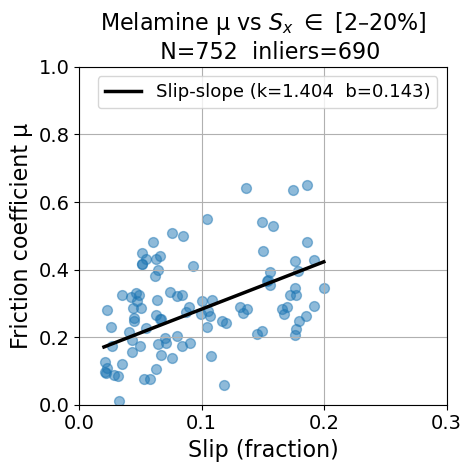

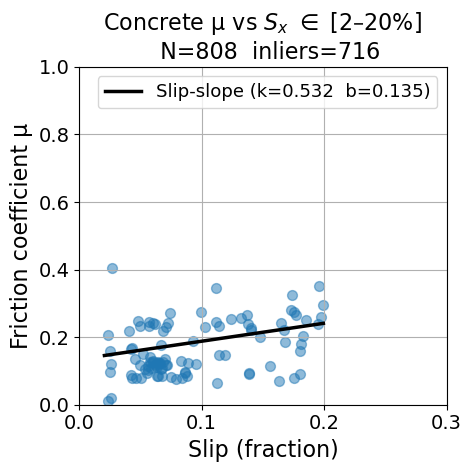

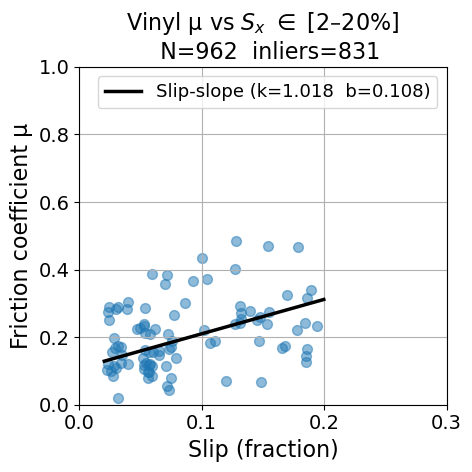

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RANSACRegressor, LinearRegression
import statsmodels.api as sm
import sys
import os
import pickle
import plotly.graph_objects as go
from scipy.interpolate import UnivariateSpline


def slip_mu_ransac(
    mu_df: pd.DataFrame,
    slip_df: pd.DataFrame,
    pair_map: dict[str, str],
    *,
    mass: float = 40.279,
    radius: float = 0.127,
    slip_range: tuple[int, int] = (5, 100),
    max_trials: int = 100_000,
    random_state: int | None = 42,
    slip_sign: str = 'any',  # ← NEW ARG
    plot: bool = True,
    ax: plt.Axes | None = None,
    title: str | None = None,
    surface_name: str | None = None,
):
    """
    Robustly fit μ = k·s + b with RANSAC.
    """
    # ── BASIC INDEX SANITY ──────────────────────────────────────
    for name, tbl in {"mu_df": mu_df, "slip_df": slip_df}.items():
        idx = tbl.index
        print(
            f"[idx-check] {name}: {type(idx).__name__}, "
            f"len={len(idx)}, dups={idx.has_duplicates}, "
            f"mono={idx.is_monotonic_increasing}"
        )

    # ---------- align & filter --------------------------------------------
    if isinstance(slip_df.columns, pd.MultiIndex):
        slip_df = slip_df.droplevel(0, axis=1)

    frames = []
    for mu_col, sl_col in pair_map.items():
        μ = mu_df[mu_col].reindex(slip_df.index).interpolate("index")
        # ── INTERPOLATION DIAGNOSTICS ───────────────────────────
        n_missing = μ.isna().sum()
        print(f"[missing-pre] {mu_col}: {n_missing}/{len(μ)} NaNs after reindex")
        frames.append(pd.DataFrame({"slip_pct": slip_df[sl_col], "mu": μ}))
        post_interp_missing = frames[-1]["mu"].isna().sum()
        print(f"[missing-post] {mu_col}: {post_interp_missing} NaNs after interpolate → DataFrame")

    df = pd.concat(frames).dropna()

    df["slip_frac"] = df["slip_pct"] / 100.0

    # if slip_sign == 'any':
    #     df["slip_frac"] = df["slip_frac"].abs()

    zero_rows = df["slip_frac"] == 0
    if zero_rows.any():
        print(f"[zap] removing {zero_rows.sum()} rows at slip=0")
        df = df[~zero_rows]



    # # ----- kill rows with tiny μ -------------------------------------------
    MU_CUT = 0.01  # dimensionless
    before = len(df)
    df = df[df["mu"].abs() >= MU_CUT]
    print(f"[μ-cut] removed {before - len(df):,} rows (|μ| < {MU_CUT})")

    # # ── FILTER RESULT SUMMARY ───────────────────────────────────
    # print(
    #     f"[filter] kept {len(df):>6} rows "
    #     f"(μ range {df['mu'].min():.2f}…{df['mu'].max():.2f}, "
    #     f"S range {df['slip_frac'].min():.4f}…{df['slip_frac'].max():.4f})"
    # )


    bin_w = 0.05                          # 1 % slip bins
    edges = np.arange(df.slip_frac.min(), df.slip_frac.max() + bin_w, bin_w)
    df["bin"] = pd.cut(df.slip_frac, edges, right=False)

    def iqr_trim(group, fence=1.8):
        q1, q3 = group["mu"].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - fence * iqr, q3 + fence * iqr
        return group[(group["mu"] >= lo) & (group["mu"] <= hi)]

    before = len(df)
    df = (
        df.groupby("bin", group_keys=False, observed=True)
        .apply(iqr_trim)
        .drop(columns="bin")
    )
    print(f"[slice-trim] removed {before - len(df):,} vertical μ outliers")
    n_total = len(df)          # update for later printout




    # ── inside slip_mu_ransac, after `df = pd.concat(frames).dropna()` ───────
    chk = df.groupby("slip_frac")["mu"].nunique()
    perm = chk[chk > 1]
    if not perm.empty:
        clash = perm.index[:5].to_list()
        print(
            f"[pair-clash] {len(perm)} slip values map to >1 μ "
            f"(e.g. {clash}) – time alignment is borked"
        )

    if slip_sign == "pos":
        df = df[df["slip_pct"] > 0]
    elif slip_sign == "neg":
        df = df[df["slip_pct"] < 0]
    elif slip_sign == "any":
        df["slip_frac"] = df["slip_frac"].abs()
        df["mu"] = df["mu"].abs()


    # Subsample 2D bins to reduce overrepresented μ bands
    df["μ_bin"] = pd.cut(df["mu"], bins=np.linspace(-1.5, 1.5, 100))
    df["s_bin"] = pd.cut(df["slip_frac"], bins=np.linspace(df["slip_frac"].min(), df["slip_frac"].max(), 100))

    def balanced_subsample(group, max_per_bin=150):
        if len(group) > max_per_bin:
            return group.sample(n=max_per_bin, random_state=41)
        return group

    before = len(df)
    df = (
        df.groupby(["μ_bin", "s_bin"], group_keys=False, observed=True)
        .apply(balanced_subsample)
        .drop(columns=["μ_bin", "s_bin"])
    )
    print(f"[subsample] removed {before - len(df):,} overrepresented rows")



    df = df.query("mu.between(-1.5, 1.5)")
    df = df[df["slip_frac"].abs().between(slip_range[0] / 100, slip_range[1] / 100)]

    if df.empty:
        raise ValueError("No data left after filtering.")

    n_total = len(df)


    # ---------- RANSAC -----------------------------------------------------
    X = df["slip_frac"].to_numpy()[:, None]
    y = df["mu"].to_numpy()

    lin = LinearRegression().fit(X, y)
    mad = np.median(np.abs(y - lin.predict(X)))
    thr = max(3 * mad, 1e-6)
    # thr = 0.3
    print(f"Initial MAD: {mad:.4f}, Threshold: {thr:.4f}")

    ransac = RANSACRegressor(
        LinearRegression(),
        residual_threshold=thr,
        max_trials=max_trials,
        random_state=random_state,
    ).fit(X, y)

    inliers = ransac.inlier_mask_

    n_in = int(inliers.sum())
    X_in, y_in = X[inliers], y[inliers]

    ols = sm.OLS(y_in, sm.add_constant(X_in)).fit()
    ci = ols.conf_int(alpha=0.05)
    resid_std = np.sqrt(ols.mse_resid)

    k, b = ransac.estimator_.coef_[0], ransac.estimator_.intercept_

    print(
        f"[ransac] inliers = {inliers.sum():>6} / {len(inliers)} "
        f"({inliers.mean():.2%})   k={k:.4f}   b={b:.4f}"
    )

    # ---------- plot -------------------------------------------------------
    fig = None
    if plot:
        if ax is None:
            fig, ax = plt.subplots(figsize=(5, 5))
        else:
            fig = ax.figure

        # --- sample points -------------------------------------------------
        max_pts = 100
        in_idx, out_idx = np.flatnonzero(inliers), np.flatnonzero(~inliers)
        in_plot = np.random.choice(in_idx, min(len(in_idx), max_pts), False)
        out_plot = np.random.choice(out_idx, min(len(out_idx), max_pts), False)

        # ax.scatter(X[out_plot], y[out_plot], c="red", s=10, alpha=0.0, label="outlier")
        # ax.scatter(X[in_plot], y[in_plot], c="C0", s=10, alpha=0.4, label="inlier")
        ax.scatter(X[in_plot], y[in_plot], c="C0", s=50, alpha=0.5)

        # --- x-grid for lines ---------------------------------------------
        x_grid = np.linspace(X.min(), X.max(), 200)[:, None]

        # 1) ordinary least-squares on *all* points (pre-RANSAC line)
        lin = LinearRegression().fit(X, y)  # safe even if fit earlier
        # ax.plot(
        #     x_grid,
        #     lin.predict(x_grid),
        #     "g--",
        #     lw=1.8,
        #     label=f"OLS full (k={lin.coef_[0]:.3f})",
        # )

        # 2) slip-slope
        ax.plot(
            x_grid,
            ransac.predict(x_grid),
            "k-",
            lw=2.5,
            label=f"Slip-slope (k={k:.3f}  b={b:.3f})",
        )

        # --- cosmetics -----------------------------------------------------
        ax.set_xlabel("Slip (fraction)")
        ax.set_ylabel("Friction coefficient μ")
        ax.grid(True)
        ax.legend()

        min_s, max_s = slip_range
        # ax.set_xlim(-max_s * 0.01 - 0.2, max_s * 0.01 + 0.2)
        ax.set_xlim(0.0, max_s * 0.01 + 0.1)

        ax.set_ylim(0, 1)


        base = f"{surface_name} " if surface_name else ""
        tag = " (slip>0)" if slip_sign else ""
        auto_title = f"{base}μ vs $S_x$ $\in$ [{min_s}–{max_s}%]\n  N={n_total}  inliers={n_in}"
        ax.set_title(title or auto_title)
        fig.tight_layout()

        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        out_dir = "figures"
        os.makedirs(out_dir, exist_ok=True)

        filename = f"{surface_name.lower()}_{min_s}-{max_s}pct_{timestamp}.png"
        save_path = os.path.join(out_dir, filename)

        fig.savefig(save_path, dpi=300)
        print(f"[saved] {save_path}")

    return {
        "slope": k,
        "intercept": b,
        "ci_slope": tuple(ci[1]),
        "ci_intercept": tuple(ci[0]),
        "resid_std": resid_std,
        "inlier_frac": inliers.mean(),
        "paired": df,
        "inlier_mask": inliers,
        "figure": fig,
    }


include_substrings = [
    # "0.001amp",
    # "0.01amp",
    # '3.0a',
    "0.5hz",
    "0.8hz",
    "1.0hz",
    '1.2hz',
    '1.5hz',
    "1.8hz",
    "2.0hz",
]  # modify as needed


# Open all the pickles and plot all our purdy plots.
results_dir = "results/2025_06_29_15_25_12"
# Changed K_T to be higher.
# results_dir = "results/2025_06_29_15_49_30"
# lower 20Hz low pass on current. Less motor smoothing. Fix outlier removal?
# results_dir = "results/2025_06_29_17_16_40"
# results_dir = "results/2025_06_29_20_53_41"
# results_dir = 'results/2025_06_29_22_29_03'
pickles_path = {
    "Melamine": f"{results_dir}/melamine",
    "Concrete": f"{results_dir}/concrete",
    "Vinyl": f"{results_dir}/vinyl",
}

# robot & patch parameters
mass = 40.279  # kg
F_N_net = 9.81 * mass  # total normal force (N)
F_N = F_N_net / 4  # per patch
radius = 0.127  # m

summary = []

# robot & patch parameters
mass = 40.279  # kg
F_N_net = 9.81 * mass  # total normal force (N)
F_N = F_N_net / 4  # per patch
radius = 0.127  # m

for surface, pickles_path in pickles_path.items():
    # List all .pkl files
    # pkl_files = [f for f in os.listdir(pickles_path) if f.endswith(".pkl")]
    all_files = [f for f in os.listdir(pickles_path) if f.endswith(".pkl")]
    pkl_files = [f for f in all_files if any(substr in f for substr in include_substrings)]
    # pkl_files = all_files

    print(pkl_files)

    contents = []
    for fname in pkl_files:
        fpath = os.path.join(pickles_path, fname)

        with open(fpath, "rb") as f:
            obj = pickle.load(f)
            contents.append(obj)

    # Combine Everything
    pair_map = {
        "left_front_torque": "fl_vx",
        "right_front_torque": "fr_vx",
        "left_back_torque": "bl_vx",
        "right_back_torque": "br_vx",
    }

    # Hold all the mu and slip merged in from all the other dataframs.
    all_mu = pd.DataFrame()
    all_slip = pd.DataFrame()

    for each in contents:
        final_df = each["final_df"]
        torq_df = final_df["motor_torques_combined"][pair_map.keys()]

        mu_df = (torq_df / radius) / F_N  # dimensionless μ
        slip_df = final_df["slip_unbiased"]

        if isinstance(slip_df.columns, pd.MultiIndex):
            slip_df = slip_df.droplevel(0, axis=1)
        slip_df = slip_df[list(pair_map.values())]

        all_mu = pd.concat([all_mu, mu_df], axis=0)
        all_slip = pd.concat([all_slip, slip_df], axis=0)

        all_mu = _dedup(all_mu)
        all_slip = _dedup(all_slip)
        all_mu = all_mu.sort_index()
        all_slip = all_slip.sort_index()

        # ── CONCAT SUMMARY ──────────────────────────────────────────
        for name, tbl in {"all_mu": all_mu, "all_slip": all_slip}.items():
            print(
                f"[concat] {surface} → {name}: shape={tbl.shape}, "
                f"idx_dups={tbl.index.has_duplicates}, "
                f"idx_mono={tbl.index.is_monotonic_increasing}"
            )

    slip_ranges = [
        # (1, 5),
        # (0.1, 5),
        # (5, 20),
        # (2, 100),
        # (3, 100),
        # (4, 100),
        # (5,20),
        (2,20),
        # (5,20),
        # (1, 5),
        # (4, 20),
        # (1, 2),
        # (0.1, 1),
        # (1, 30),
        # (5, 80),
    ]

    # fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
    # fig.suptitle(f"{surface}: RANSAC fits for slip range {min_s}%–{max_s}%", fontsize=16)

    # for min_s, max_s in slip_ranges:
    #     results = {}
    #     # iterate wheels & corresponding axes
    #     for ax, (mu_col, sl_col) in zip(axes.flatten(), pair_map.items()):
    #         # single‐wheel pair_map
    #         single_map = {mu_col: sl_col}
    #         res = slip_mu_ransac(
    #             mu_df=mu_df.sort_index(),
    #             slip_df=slip_df.sort_index(),
    #             pair_map=single_map,
    #             slip_range=(min_s, max_s),
    #             surface_name=surface,
    #             slip_sign='pos',
    #             plot=True,
    #             ax=ax,
    #             title=mu_col  # wheel name as subplot title
    #         )
    #         results[mu_col] = res

    # print(
    #     f"[call] {surface}: slip_range={min_s}-{max_s}%  "
    #     f"rows μ={len(all_mu):>6}  rows slip={len(all_slip):>6}"
    # )

    # Plot with all the data
    for min_s, max_s in slip_ranges:
        # slip_mu_ransac_plotly_3d(
        slip_mu_ransac(
            # slip_mu_mean_line(
            mu_df=all_mu.sort_index(),
            slip_df=all_slip.sort_index(),
            pair_map=pair_map,
            slip_range=(min_s, max_s),
            surface_name=surface,
            slip_sign='pos'
            # positive_only=True,
            # smooth=True,
            # wrap_abs=True,
            # n_bins=30,
            # spline_s=.05
        )


In [33]:
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.linear_model import RANSACRegressor, LinearRegression
# from sklearn.metrics import mean_squared_error

# # -------------------------------
# # Robot & patch parameters
# # -------------------------------
# mass = 40.0  # kg
# F_N = 9.81 * mass / 4  # per patch
# radius = 0.127  # m

# # Slip filtering thresholds
# min_s = 5
# max_s = 100
# s_min = min_s / 100
# s_max = max_s / 100

# # -------------------------------
# # μ and slip: from all_mu and all_slip
# # -------------------------------
# mu_df = all_mu.sort_index()
# slip_df = all_slip.sort_index()

# if isinstance(slip_df.columns, pd.MultiIndex):
#     slip_df = slip_df.droplevel(0, axis=1)
# slip_df = slip_df[list(pair_map.values())]

# # -------------------------------
# # Align timestamps and merge
# # -------------------------------
# records = []
# for tq_col, sl_col in pair_map.items():
#     mu_align = mu_df[tq_col].reindex(slip_df.index).interpolate("index")
#     pair = pd.DataFrame({
#         "wheel": sl_col[:-3],
#         "slip_pct": slip_df[sl_col],
#         "mu": mu_align,
#     }).dropna()
#     records.append(pair)

# paired = pd.concat(records, ignore_index=True)
# paired = paired[paired["mu"].between(-1.5, 1.5)]
# paired = paired[paired["slip_pct"].abs().between(min_s, max_s)]
# paired["slip_frac"] = paired["slip_pct"] / 100.0

# print("sample rows:", len(paired))

# # -------------------------------
# # RANSAC-based robust linear fit
# # -------------------------------
# X = paired["slip_frac"].values.reshape(-1, 1)
# y = paired["mu"].values

# # Fit regular linear model for residual estimation
# lin = LinearRegression().fit(X, y)
# resid = np.abs(y - lin.predict(X))
# mad = np.median(np.abs(resid - np.median(resid)))
# threshold = 3 * mad
# print(f"{threshold=}")

# # Fit RANSAC using adaptive threshold
# ransac = RANSACRegressor(
#     estimator=LinearRegression(),
#     residual_threshold=threshold,
#     max_trials=100000,
#     random_state=42
# )
# ransac.fit(X, y)


# import statsmodels.api as sm

# # after ransac.fit(X, y)…
# X_in = X[inlier_mask]
# y_in = y[inlier_mask]
# X_ols = sm.add_constant(X_in)               # adds intercept term
# ols_res = sm.OLS(y_in, X_ols).fit()
# print(ols_res.summary())                    # shows slope SE, t-stat, p-value
# ci = ols_res.conf_int(alpha=0.05)           # 95% CI on intercept & slope
# print("95% CI (const, slope):\n", ci)


# inlier_mask = ransac.inlier_mask_
# outlier_mask = ~inlier_mask

# # Downsample for clarity
# max_plot = 2000
# in_idx = np.flatnonzero(inlier_mask)
# out_idx = np.flatnonzero(outlier_mask)
# in_plot = np.random.choice(in_idx, size=min(len(in_idx), max_plot), replace=False)
# out_plot = np.random.choice(out_idx, size=min(len(out_idx), max_plot), replace=False)

# # Extract fit
# slip_in = X[inlier_mask].flatten()
# mu_in = y[inlier_mask]
# k = ransac.estimator_.coef_[0]
# b = ransac.estimator_.intercept_

# print(f"μ = {k:.3f}·s + {b:.3f}  (RANSAC fit)")
# print(f"Kept {inlier_mask.sum()} / {len(inlier_mask)} points ({100 * inlier_mask.mean():.1f}% inliers)")

# resid_var = ols_res.mse_resid
# resid_std = np.sqrt(resid_var)
# print(f"Residual variance = {resid_var:.6f}")
# print(f"Residual standard deviation = {resid_std:.3f}")

# # -------------------------------
# # Plot
# # -------------------------------
# plt.figure(figsize=(6, 4))
# plt.scatter(X[out_plot], y[out_plot], c="red", s=10, alpha=0.4, label="outlier")
# plt.scatter(X[in_plot], y[in_plot], c="C0", s=10, alpha=0.4, label="inlier")

# xs = np.linspace(slip_in.min(), slip_in.max(), 200).reshape(-1, 1)
# ys = ransac.predict(xs)

# plt.plot(xs, ys, "k-", lw=2, label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction coefficient μ")
# plt.title(f"Melamine μ vs Slip (RANSAC)\n{min_s}–{max_s}% slip window")
# plt.grid(True)
# plt.axis("square")
# plt.legend()
# plt.tight_layout()

# # Optional save
# # plt.gcf().savefig(metadata['artifact_dir'] + f"/{k}_ransac_slip_slope_min_{min_s}_max{max_s}.png", dpi=300, bbox_inches="tight")

# plt.show()
